# Lab 1: Contour Features of Chromosomes

MLPR, Semester 4. Detects chromosomes in a microscope image using morphological opening, thresholding and contours. Then extracts shape features (height, width, area, perimeter, circularity) and compares standardisation with min-max normalisation.

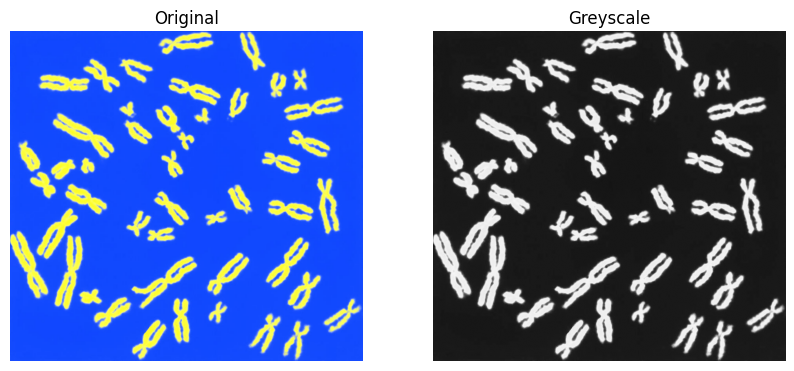

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler

img = cv2.imread("data/chromosomes.jpg")
grey_image = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0].set_title("Original")
axes[1].imshow(grey_image, cmap="gray"); axes[1].set_title("Greyscale")
for ax in axes: ax.axis("off")
plt.show()

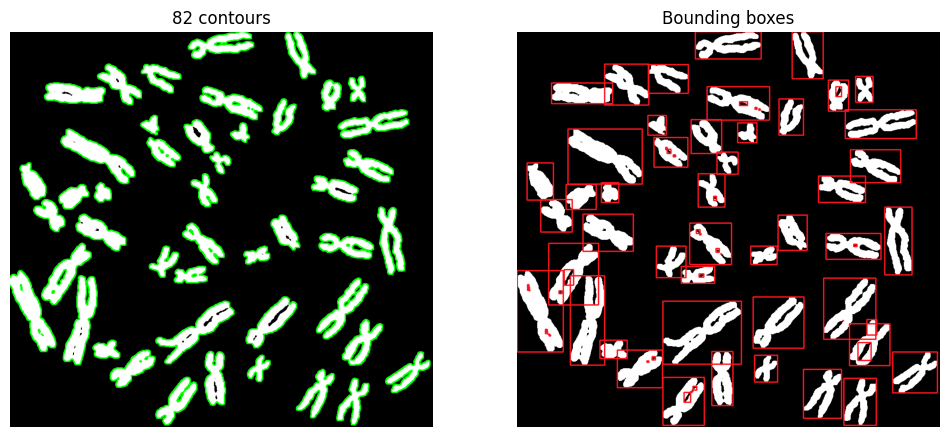

In [2]:
# Morphological opening removes small specks, then a binary threshold separates chromosomes
kernel = np.ones((5, 5), np.uint8)
changed_img = cv2.morphologyEx(grey_image, cv2.MORPH_OPEN, kernel)
ret, binary_img = cv2.threshold(changed_img, 127, 255, cv2.THRESH_BINARY)

edged = cv2.Canny(binary_img, 100, 200)
contours, _ = cv2.findContours(edged, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

color_img = cv2.cvtColor(binary_img, cv2.COLOR_GRAY2BGR)
cv2.drawContours(color_img, contours, -1, (0, 255, 0), 2)
box = cv2.cvtColor(binary_img, cv2.COLOR_GRAY2BGR)
for contour in contours:
    x, y, w, h = cv2.boundingRect(contour)
    cv2.rectangle(box, (x, y), (x + w, y + h), (255, 20, 30), 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB)); axes[0].set_title(f"{len(contours)} contours")
axes[1].imshow(box); axes[1].set_title("Bounding boxes")
for ax in axes: ax.axis("off")
plt.savefig("images/lab01_contours.png", bbox_inches="tight")
plt.show()

In [3]:
features = []
for contour in contours:
    x, y, w, h = cv2.boundingRect(contour)
    area = cv2.contourArea(contour)
    peri = cv2.arcLength(contour, True)
    circ = (4 * np.pi * area) / (peri ** 2) if peri != 0 else 0
    features.append({"Height": h, "Width": w, "Area": area, "Perimeter": peri, "Circularity": circ})

features_df = pd.DataFrame(features)
features_df.round(3).head(10)

,Height,Width,Area,Perimeter,Circularity
0,21,14,9.5,98.468,0.012
1,1,1,0.0,0.000,0.000
2,2,1,0.0,2.000,0.000
3,1,1,0.0,0.000,0.000
4,8,8,0.5,22.728,0.012
5,100,69,2687.0,414.877,0.196
6,102,88,56.5,717.051,0.001
7,104,81,3028.5,435.345,0.201
8,3,4,0.5,13.071,0.037
9,7,7,3.0,34.627,0.031


In [4]:
standardized_df = pd.DataFrame(StandardScaler().fit_transform(features_df), columns=features_df.columns)
normalized_df = pd.DataFrame(MinMaxScaler().fit_transform(features_df), columns=features_df.columns)
print("Standardised (mean 0, std 1):")
print(standardized_df.describe().loc[["mean", "std"]].round(3))
print("\nMin-max normalised (range 0 to 1):")
print(normalized_df.describe().loc[["min", "max"]].round(3))

Standardised (mean 0, std 1):
      Height  Width   Area  Perimeter  Circularity
mean  -0.000  0.000  0.000     -0.000        0.000
std    1.006  1.006  1.006      1.006        1.006

Min-max normalised (range 0 to 1):
     Height  Width  Area  Perimeter  Circularity
min     0.0    0.0   0.0        0.0          0.0
max     1.0    1.0   1.0        1.0          1.0


## Observations

- Contours with a circularity close to 0 (very long perimeter for a tiny area) are leftover noise rather than chromosomes.
- Larger height or width usually means a larger area.
- A high area does not always mean a high perimeter. Bends and indents add perimeter without adding area.

## Report

**A1.** Contours outline and separate individual objects, so they can be used for object detection, especially in 2D images.

**A2.** Standardisation puts all features on the same scale. Otherwise features with large values (such as area) would dominate distance-based methods like clustering.

**A3.** Missing values can be filled with a statistic of the column (mean or median), or the affected rows can be removed.

**A4.** Normalisation (min-max scaling) rescales each feature to a fixed range, usually 0 to 1, so that no feature dominates because of its units. Standardisation instead gives each feature a mean of 0 and a standard deviation of 1.

**A5.** Use object recognition to detect and label each chromosome individually. Apply contour detection to outline each one, and separate overlapping contours, for example with watershed segmentation.